<a href="https://colab.research.google.com/github/Eli39603/insurance-claims-ml/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

path = '/content/drive/MyDrive/פרויקט - למידת מכונה/dataset_class.csv'
dataset = pd.read_csv(path)

print(dataset.shape)
dataset.head()

Mounted at /content/drive
(45000, 30)


,customer_id_hash,agent_code,country,area_type,region_density,winter_severity,driver_age,gender,marital_status,license_years,...,annual_km_estimated,pct_intercity,pct_night_driving,parking_type,current_premium,claim_count,at_fault,days_to_settlement,police_report_filed,annual_claim_cost
0,6db089eb,A043,ES,suburban,855,1.3,75,F,widowed,54,...,7500.0,5,15,lot,4450,1,0.0,27.0,0.0,6178
1,d3a860d7,A057,GB,suburban,1225,2.7,76,M,married,45,...,3000.0,25,10,street,1630,0,NaN,NaN,NaN,0
2,f0610253,A186,IL,suburban,1651,1.9,60,M,single,42,...,12500.0,0,5,garage,980,0,NaN,NaN,NaN,0
3,3137c022,A002,JP,urban,5441,7.7,55,M,divorced,34,...,10000.0,5,5,street,1810,0,NaN,NaN,NaN,0
4,a1513621,A028,FR,urban,3231,5.9,69,M,widowed,51,...,NaN,5,40,street,12290,0,NaN,NaN,NaN,0


### 2. Input data

**2-a** We loaded the file from Google Drive. It has 45,000 drivers and 30 columns.

In [ ]:
# Load - pd.read_csv()

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.patches as mpatches
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split

dataset = pd.read_csv(path)
print(dataset.head())
print(dataset.describe())

### 2.2 Data Leakage Analysis

To predict `annual_claim_cost` for a **new** policy, we must exclude any fields that are only known **after** a claim is filed or during the policy term.

**Fields to drop (Leakage & Identifiers):**
* `customer_id_hash`: Unique identifier (no predictive power, can cause overfitting).
* `claim_count`: Future information (known only after the policy term starts).
* `at_fault`: Post-accident detail.
* `days_to_settlement`: Post-accident detail.
* `police_report_filed`: Post-accident detail.
* `annual_claim_cost`: The target variable itself.
* **`current_premium`:** In standard insurance, the `current_premium` is calculated and paid **upfront** at policy inception. Because it is known at the time of issuing a new policy, it does not violate leakage rules. We decided to drop it because we are trying to build an unbiased, independent "pure premium" risk model from raw driver behaviors, without letting the existing premium framework influence the predictions.

> ⚠️ **To review (current_premium):** the data dictionary says this is the premium paid at the **end** of the policy year, so it is not known when a new policy starts. Suggested wording: *"According to the data dictionary, this is the premium paid at the end of the policy year. It is not known when a new policy starts, so using it would be data leakage."*

In [ ]:
# Separate features and target while preventing data leakage
# use this in prepare_data func

leakage_and_id_cols = [
    'customer_id_hash',
    'claim_count',
    'at_fault',
    'days_to_settlement',
    'police_report_filed',
    'current_premium'
]

target_col = 'annual_claim_cost'

# Features (X) and Target (y)
X = dataset.drop(columns=leakage_and_id_cols + [target_col])
y = dataset[target_col]

print("Features available for training (excluding leakages):")
print(list(X.columns))
print(X)
print(y)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id_hash       45000 non-null  object 
 1   agent_code             45000 non-null  object 
 2   country                45000 non-null  object 
 3   area_type              45000 non-null  object 
 4   region_density         45000 non-null  int64  
 5   winter_severity        45000 non-null  float64
 6   driver_age             45000 non-null  int64  
 7   gender                 45000 non-null  object 
 8   marital_status         45000 non-null  object 
 9   license_years          45000 non-null  int64  
 10  prior_claims_5y        41858 non-null  float64
 11  no_claims_years        45000 non-null  int64  
 12  violations_3y          45000 non-null  int64  
 13  vehicle_type           45000 non-null  object 
 14  vehicle_age            45000 non-null  int64  
 15  en

<Axes: title={'center': '% missing per column'}>

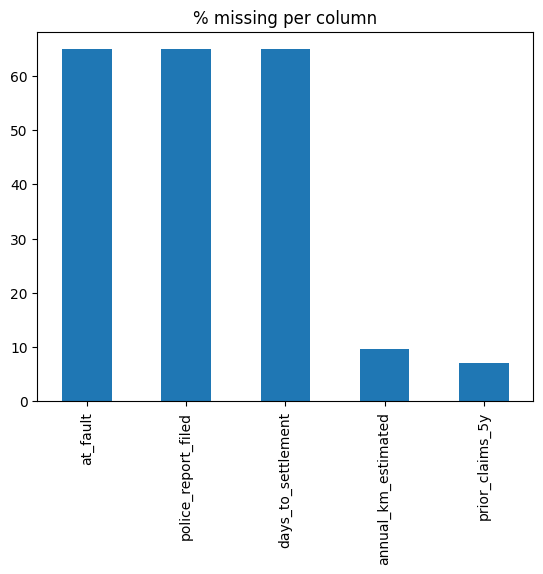

In [ ]:
dataset.info()

missing = dataset.isna().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]
print(missing.round(2))
missing.plot(kind='bar', title='% missing per column')

### 2.3 Data exploration: column types and missing values

**2.3-a** Three columns are missing in 64.9% of the rows: `at_fault`, `police_report_filed` and `days_to_settlement`. This is roughly the share of drivers with no claim, so the value is probably missing simply because there was no claim. Either way, these fields are only known after a claim (data leakage), so we will drop them from the model. See also section 2.2.

**2.3-b** Two more columns are partly missing: `annual_km_estimated` (9.6%) and `prior_claims_5y` (7.0%). We will need to fill them in. First we will check whether the missing values follow a pattern (MCAR/MAR).

**2.3-c** `vehicle_value` is stored as text (object) and not as a number, so something in this column is not clean. We will check it in the next step.

### 3. Models: draft from the 2.2 work (needs review later)

**Note:** this code and the text below it were added as-is from the partner's notebook. They belong to section 3 and still need review and fixes before we use them.

In [ ]:
# preventing Data leakage in pipeline cross validation

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score
from sklearn.model_selection import StratifiedKFold

# ŷ = w0 + w1x + w2x2 + … + wdxd
# w0 … wd   coefficients, learned from the data by least squares
# x, x2, …, xd   features, computed from age before fitting
# d   degree, chosen by us: a hyperparameter
# d = 1: a line    d = 2: a parabola     d = 3: a cubic


def poly_model(d):
    return make_pipeline(
        PolynomialFeatures(d, include_bias=False),
        StandardScaler(), LinearRegression())

# 1) lock away 20% as the test set
X_tv, X_test, y_tv, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)
# 2) split the rest: 75% train, 25% validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tv, y_tv, test_size=0.25, random_state=0)

val_rmse = {}

for d in range(1, 9):
    model = poly_model(d).fit(X_tr, y_tr)
y_hat = model.predict(X_val)
val_rmse[d] = root_mean_squared_error(y_val, y_hat)
best_d = min(val_rmse, key=val_rmse.get)
print(best_d)


cv = KFold(n_splits=5, shuffle=True, random_state=0)

model = make_pipeline(
    PolynomialFeatures(d),
    StandardScaler(),
    LinearRegression()
)
cross_val_score(model, X, y, cv=cv)


We use fit_transform(X_train) to compute the mean and standard deviation only from the training set, and then scale it.
We then use transform(X_test) on the test set. This ensures that no information from the test set (like its mean or range) leaks into the training phase (preventing data leakage).
* **The Pipeline .fit() on the Training Fold (No Leakage!):**
PolynomialFeatures learns the feature structure of the training fold and transforms it.
StandardScaler calculates the mean $(\mu)$ and standard deviation $(\sigma)$ strictly from this training fold only, and scales it.
LinearRegression fits its weights using this scaled training data.
* **The Pipeline .predict() / .score() on the Validation Fold:**
PolynomialFeatures transforms the validation fold.
StandardScaler transforms the validation fold using the $(\mu)$ and $(\sigma)$ calculated earlier from the training fold (it does not recalculate mean/std on the validation fold).
LinearRegression predicts the outcomes for the validation fold and calculates the score (by default, $R^2$$R^2$ score for regression).